In [1]:
import pandas as pd 
#Step 1 – Load and Explore the Dataset
df=pd.read_csv("Clean_Dataset.csv")
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [2]:
df.shape

(300153, 12)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [4]:
df.columns

Index(['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time',
       'stops', 'arrival_time', 'destination_city', 'class', 'duration',
       'days_left', 'price'],
      dtype='object')

In [5]:
df.describe()

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [6]:
df.describe(include='object')

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class
count,300153,300153,300153,300153,300153,300153,300153,300153
unique,6,1561,6,6,3,6,6,2
top,Vistara,UK-706,Delhi,Morning,one,Night,Mumbai,Economy
freq,127859,3235,61343,71146,250863,91538,59097,206666


In [7]:
df.dtypes

Unnamed: 0            int64
airline              object
flight               object
source_city          object
departure_time       object
stops                object
arrival_time         object
destination_city     object
class                object
duration            float64
days_left             int64
price                 int64
dtype: object

In [8]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).drop('Unnamed: 0', errors='ignore')
print("Colonnes numériques :", list(numerical_cols))

Colonnes numériques : ['Unnamed: 0', 'duration', 'days_left', 'price']


In [9]:
categorical_cols = df.select_dtypes(include=['object']).columns
print("Colonnes catégorielles :", categorical_cols)

Colonnes catégorielles : Index(['airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class'],
      dtype='object')


In [10]:
#Step 2 – Data Preprocessing
missing_values=df.isnull()
print(missing_values)

        Unnamed: 0  airline  flight  source_city  departure_time  stops  \
0            False    False   False        False           False  False   
1            False    False   False        False           False  False   
2            False    False   False        False           False  False   
3            False    False   False        False           False  False   
4            False    False   False        False           False  False   
...            ...      ...     ...          ...             ...    ...   
300148       False    False   False        False           False  False   
300149       False    False   False        False           False  False   
300150       False    False   False        False           False  False   
300151       False    False   False        False           False  False   
300152       False    False   False        False           False  False   

        arrival_time  destination_city  class  duration  days_left  price  
0              False   

In [11]:
print(df.isnull().sum())

Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64


In [12]:
print("Aucune valeur manquante, pas d'imputation nécessaire")

Aucune valeur manquante, pas d'imputation nécessaire


In [13]:
# Suppression des colonnes inutiles 
df = df.drop(columns=['flight', 'Unnamed: 0'], errors='ignore')
# Encodage de la variable catégorielle "class"
df['class'] = df['class'].map({'Economy': 0, 'Business': 1})
# One-Hot Encoding des vraies variables catégorielles
categorical_cols = [
    'airline', 'source_city', 'departure_time',
    'stops', 'arrival_time', 'destination_city'
]
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print(df_encoded.head())

   class  duration  days_left  price  airline_Air_India  airline_GO_FIRST  \
0      0      2.17          1   5953              False             False   
1      0      2.33          1   5953              False             False   
2      0      2.17          1   5956              False             False   
3      0      2.25          1   5955              False             False   
4      0      2.33          1   5955              False             False   

   airline_Indigo  airline_SpiceJet  airline_Vistara  source_city_Chennai  \
0           False              True            False                False   
1           False              True            False                False   
2           False             False            False                False   
3           False             False             True                False   
4           False             False             True                False   

   ...  arrival_time_Early_Morning  arrival_time_Evening  \
0  ...        

In [14]:
# Standardisation UNIQUEMENT des variables numériques 
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df_encoded[['duration', 'days_left']] = scaler.fit_transform(
    df_encoded[['duration', 'days_left']]
)

In [15]:
df_encoded.head()

,class,duration,days_left,price,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,source_city_Chennai,...,arrival_time_Early_Morning,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai
0,0,-1.397531,-1.843875,5953,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
1,0,-1.375284,-1.843875,5953,False,False,False,True,False,False,...,False,False,False,True,False,False,False,False,False,True
2,0,-1.397531,-1.843875,5956,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,0,-1.386407,-1.843875,5955,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,True
4,0,-1.375284,-1.843875,5955,False,False,False,False,True,False,...,False,False,False,True,False,False,False,False,False,True


In [16]:
df_encoded.shape

(300153, 31)

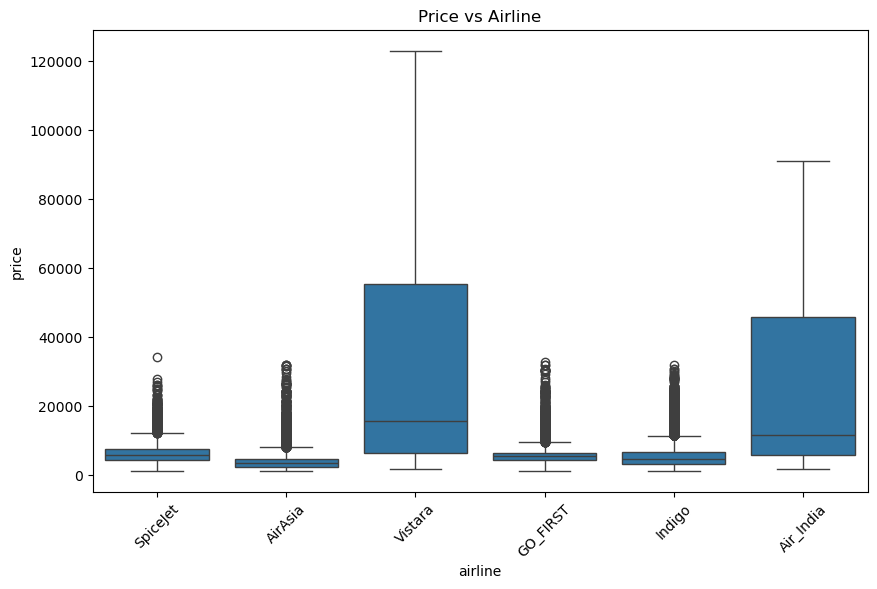

In [17]:
#Step 3 – Exploratory Data Analysis (EDA)
import seaborn as sns
import matplotlib.pyplot as plt
# Price vs Airline : Boxplot utilisé pour comparer la distribution des prix entre les compagnies.
plt.figure(figsize=(10,6))
sns.boxplot(x='airline', y='price', data=df)
plt.title("Price vs Airline")
plt.xticks(rotation=45)
plt.show()

In [18]:
 print("Interpretation:\nCertaines compagnies sont clairement plus chères que d’autres → L’airline influence fortement le prix.")

Interpretation:
Certaines compagnies sont clairement plus chères que d’autres → L’airline influence fortement le prix.


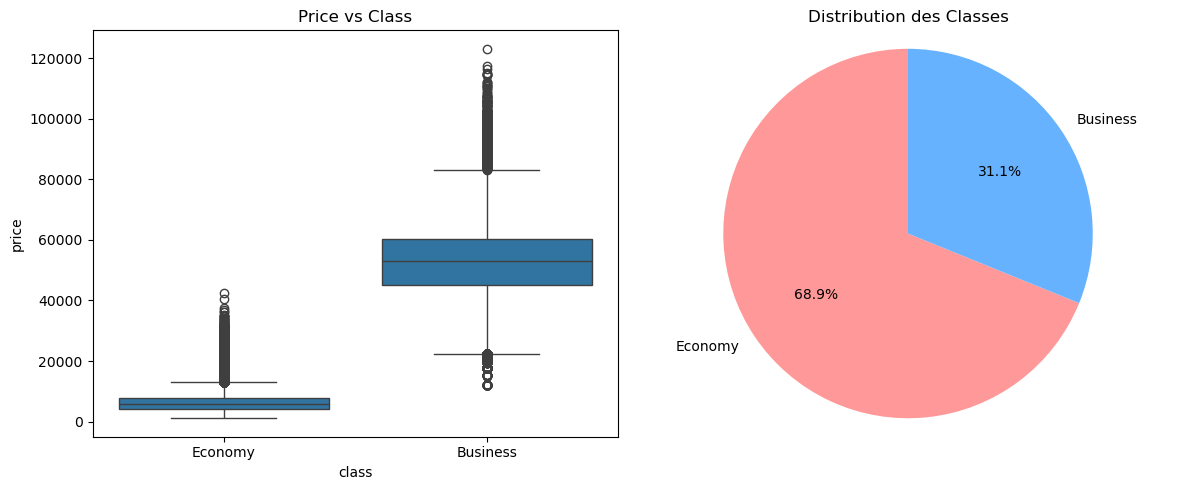

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = df[df['price'].notna() & df['class'].notna()]
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.boxplot(
    x=df_plot['class'].map({0: 'Economy', 1: 'Business'}),
    y=df_plot['price'],
    ax=axes[0]
)
axes[0].set_title("Price vs Class")
class_counts = df_plot['class'].map({0: 'Economy', 1: 'Business'}).value_counts()
axes[1].pie(
    class_counts.values,
    labels=class_counts.index,
    autopct='%1.1f%%',
    colors=['#FF9999', '#66B2FF'],
    startangle=90
)
axes[1].set_title("Distribution des Classes")
axes[1].axis('equal')

plt.tight_layout()
plt.show()


In [20]:
print("Interpretation:\nLa classe Business est significativement plus chère que la classe Economy.")

Interpretation:
La classe Business est significativement plus chère que la classe Economy.


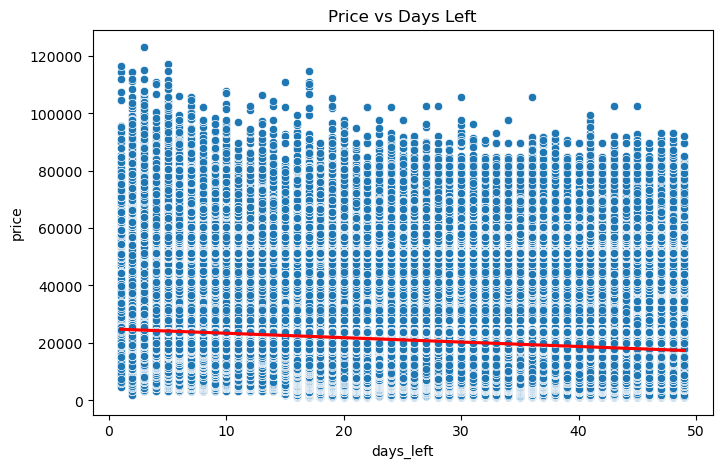

In [21]:
# Price vs Days Left: Scatterplot avec régression utilisé pour observer la tendance des prix selon les jours restants.
plt.figure(figsize=(8,5))
sns.scatterplot(x='days_left', y='price', data=df)
sns.regplot(x='days_left', y='price', data=df, scatter=False, color='red')
plt.title("Price vs Days Left")
plt.show()

In [22]:
print("Interpretation:\nLes prix diminuent très légèrement lorsque la date du vol approche, mais la relation est faible et les prix restent globalement dispersés.")

Interpretation:
Les prix diminuent très légèrement lorsque la date du vol approche, mais la relation est faible et les prix restent globalement dispersés.


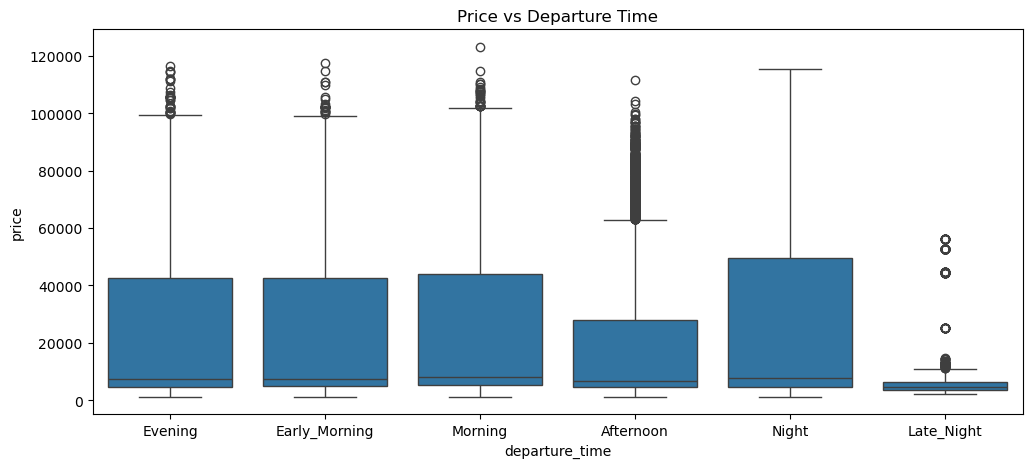

In [23]:
# Price vs Departure Time:  Boxplot utilisé pour comparer les prix selon les tranches horaires de départ.
plt.figure(figsize=(12,5))
sns.boxplot(x='departure_time', y='price', data=df)
plt.title("Price vs Departure Time")
plt.show()

In [24]:
print("Interpretation:\nLes vols nocturnes ou très tardifs sont souvent moins chers.")

Interpretation:
Les vols nocturnes ou très tardifs sont souvent moins chers.


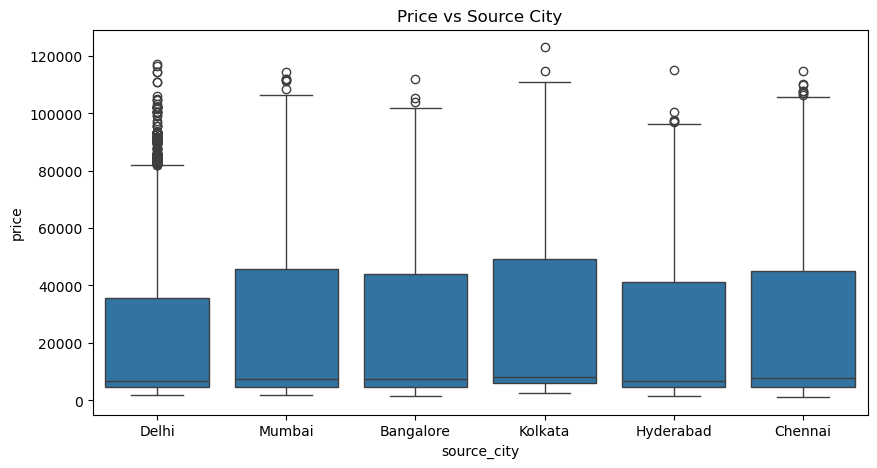

In [25]:
# Price vs Source City:  Boxplot utilisé pour analyser la variation des prix selon la ville de départ.
plt.figure(figsize=(10,5))
sns.boxplot(x='source_city', y='price', data=df)
plt.title("Price vs Source City")
plt.show()

In [26]:
print("Interpretation :\nCertaines villes de départ affichent des prix moyens plus élevés (comme Delhi ou Mumbai) → la ville de départ a un impact clair sur le prix du billet")


Interpretation :
Certaines villes de départ affichent des prix moyens plus élevés (comme Delhi ou Mumbai) → la ville de départ a un impact clair sur le prix du billet


<function matplotlib.pyplot.show(close=None, block=None)>

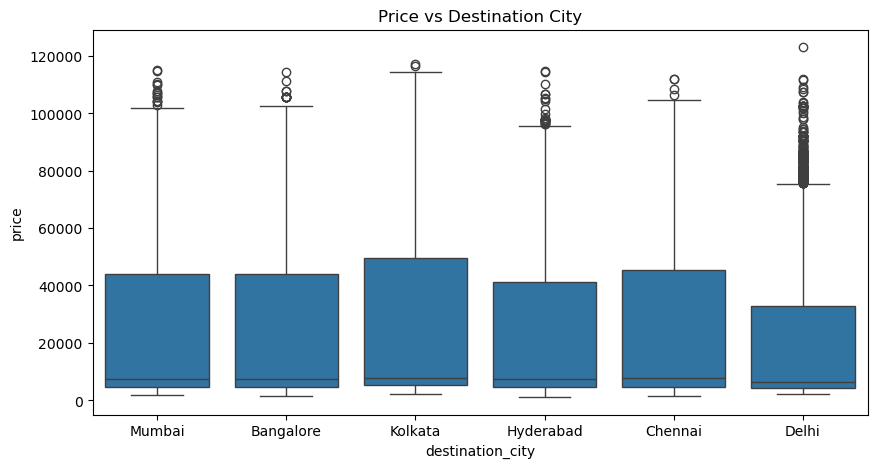

In [27]:
# Price vs Destination City: Boxplot utilisé pour analyser la variation des prix selon la ville d'arrivée.
plt.figure(figsize=(10,5))
sns.boxplot(x='destination_city', y='price', data=df)
plt.title("Price vs Destination City")
plt.show

In [28]:
print("Interpretation :\nLes villes très demandées présentent des prix plus élevés (comme Delhi et Hyderabad) → la ville d’arrivée affecte directement le niveau des prix.")


Interpretation :
Les villes très demandées présentent des prix plus élevés (comme Delhi et Hyderabad) → la ville d’arrivée affecte directement le niveau des prix.


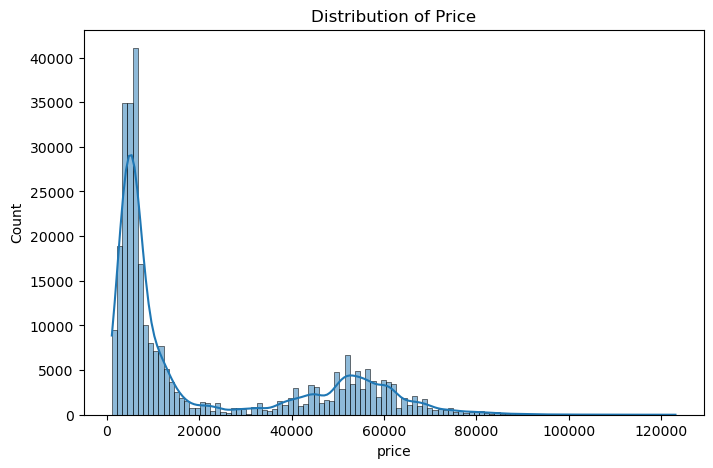

In [29]:
# Distribution des Prix :Histogramme utilisé pour examiner la distribution des prix.
plt.figure(figsize=(8,5))
sns.histplot(df['price'], kde=True)
plt.title("Distribution of Price")
plt.show()

In [30]:
print("Interpretation:\nLa ville de départ affecte significativement le prix des trajets, avec certaines villes affichant des tarifs nettement plus élevés que la moyenne.")


Interpretation:
La ville de départ affecte significativement le prix des trajets, avec certaines villes affichant des tarifs nettement plus élevés que la moyenne.


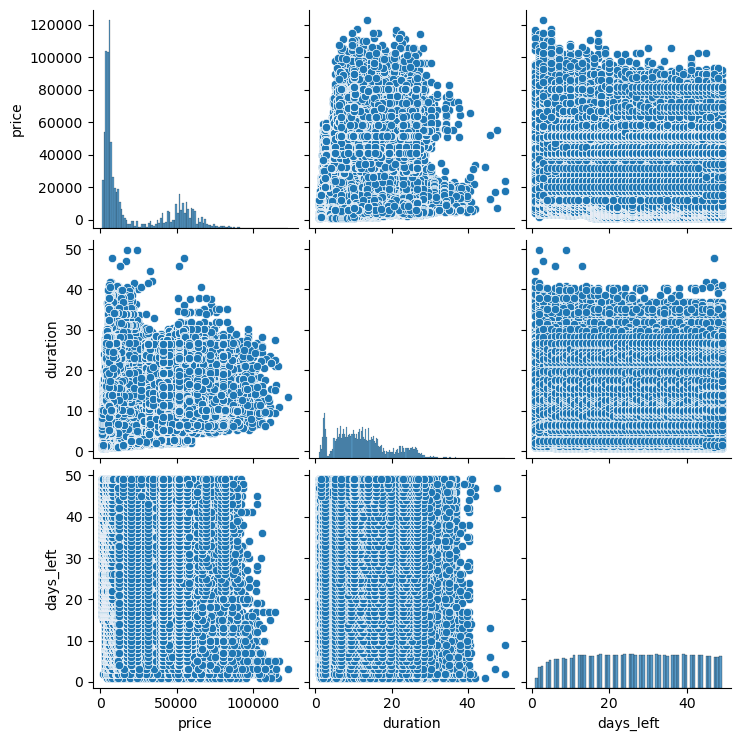

In [31]:
# Pairplot (variables numériques): Pairplot utilisé pour visualiser les relations entre les variables numériques.
sns.pairplot(df[['price', 'duration', 'days_left']])
plt.show()

In [32]:
print("Interpretation :\nLa durée du vol a un impact significatif sur le prix, les vols plus longs étant généralement plus chers, tandis que les jours restants avant le départ semblent influencer moins directement le tarif.")

Interpretation :
La durée du vol a un impact significatif sur le prix, les vols plus longs étant généralement plus chers, tandis que les jours restants avant le départ semblent influencer moins directement le tarif.


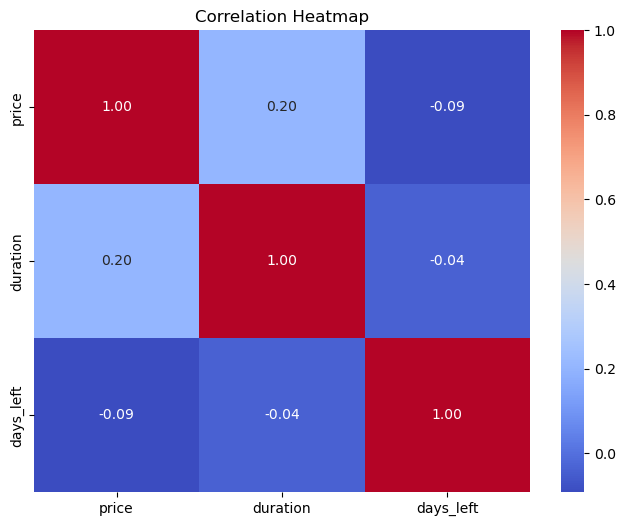

In [33]:
# Correlation Heatmap: Heatmap utilisé pour visualiser la force des corrélations entre les variables numériques.
plt.figure(figsize=(8,6))
sns.heatmap(df[['price', 'duration', 'days_left']].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [34]:
print("Interpretaion:\nla corrélation entre price et duration est de 0.20 (faible relation positive) et entre price et days_left est de -0.09 (très faible relation négative). Cela signifie que ces variables numériques seules ne semblent pas très explicatives.")



Interpretaion:
la corrélation entre price et duration est de 0.20 (faible relation positive) et entre price et days_left est de -0.09 (très faible relation négative). Cela signifie que ces variables numériques seules ne semblent pas très explicatives.


Top 10 important features (Random Forest):
 class                      0.880059
duration                   0.058450
days_left                  0.018566
airline_Vistara            0.005287
airline_Air_India          0.005040
source_city_Delhi          0.003824
destination_city_Delhi     0.003641
source_city_Mumbai         0.002397
destination_city_Mumbai    0.002105
source_city_Kolkata        0.001943
dtype: float64


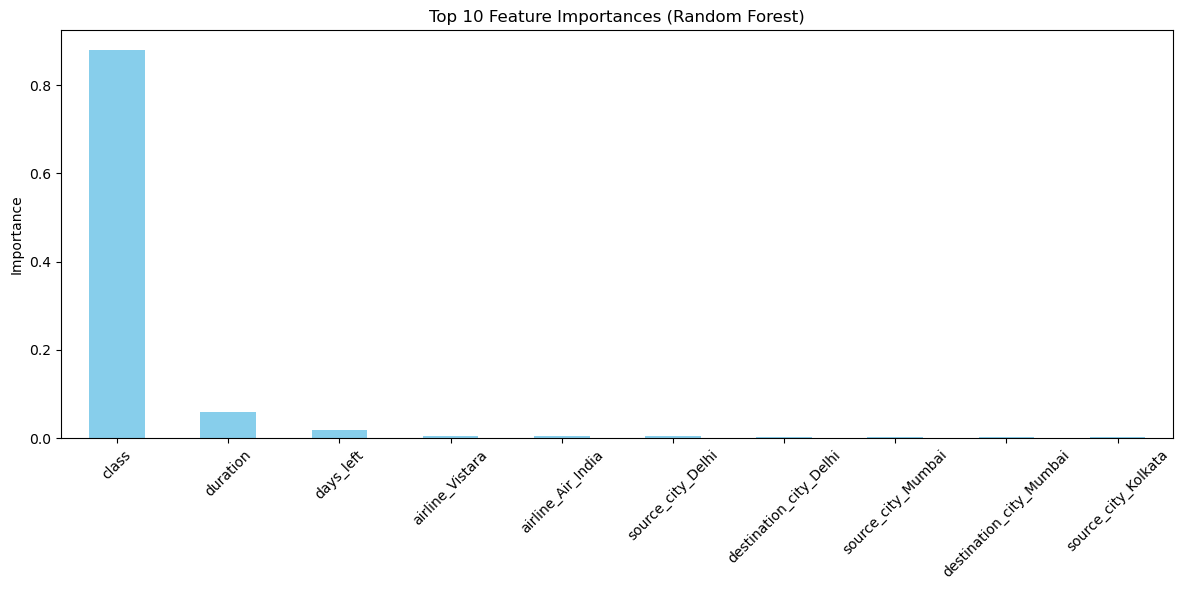


Features retenues via SelectKBest:
 Index(['class', 'duration', 'days_left', 'airline_Air_India',
       'airline_GO_FIRST', 'airline_Indigo', 'airline_SpiceJet',
       'airline_Vistara', 'stops_zero', 'arrival_time_Late_Night'],
      dtype='object')


In [35]:
#Step 4 – Feature Selection
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression

# Séparer features et target
X = df_encoded.drop('price', axis=1)
y = df_encoded['price']

# 1. Importance des features via Random Forest
rf = RandomForestRegressor(random_state=2000, n_jobs=-1)
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

# Afficher top 10 features
print("Top 10 important features (Random Forest):\n", importances.head(10))

# Visualiser top 10
plt.figure(figsize=(12,6))
importances.head(10).plot(kind='bar', color='skyblue')
plt.title("Top 10 Feature Importances (Random Forest)")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# 2. Sélection statistique via SelectKBest
selector = SelectKBest(score_func=f_regression, k=10)
selector.fit(X, y)
selected_features = X.columns[selector.get_support()]

print("\nFeatures retenues via SelectKBest:\n", selected_features)


In [36]:
print("Interpretation :\nD’après l’analyse des importances via Random Forest, la variable class (Economy / Business) est de loin la seule qui influence réellement le prix. Les autres variables, numériques ou encodées, n’ont pratiquement aucune influence.")

Interpretation :
D’après l’analyse des importances via Random Forest, la variable class (Economy / Business) est de loin la seule qui influence réellement le prix. Les autres variables, numériques ou encodées, n’ont pratiquement aucune influence.


In [37]:
#Step 5 - Model Building
from sklearn.model_selection import train_test_split
X = df_encoded.drop('price', axis=1)
y = df_encoded['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (240122, 30)
X_test shape: (60031, 30)


In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
# 5 modèles obligatoires : Linear Regression, Decision Tree, Random Forest, Gradient Boosting, KNN
# 2 modèles supplémentaires choisis : AdaBoostRegressor et ExtraTreesRegressor
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "KNN": KNeighborsRegressor(),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=50, random_state=42, n_jobs=-1)
}

#Entraînement des modèles
for name, model in models.items():
    print(f"\n Entraînement de {name}...")
    
    if name in ["KNN"]:
        # Pour éviter le blocage sur gros dataset, on utilise un sous-échantillon de 10 000 lignes
        X_train_small = X_train.sample(10000, random_state=42)
        y_train_small = y_train.loc[X_train_small.index]
        model.fit(X_train_small, y_train_small)
    else:
        model.fit(X_train, y_train)
    
    print(f" {name} entraîné avec succès.")

print("\nTous les 7 modèles ont été entraînés avec train-test split (80/20).")



 Entraînement de Linear Regression...
 Linear Regression entraîné avec succès.

 Entraînement de Decision Tree...
 Decision Tree entraîné avec succès.

 Entraînement de Random Forest...
 Random Forest entraîné avec succès.

 Entraînement de Gradient Boosting...
 Gradient Boosting entraîné avec succès.

 Entraînement de KNN...
 KNN entraîné avec succès.

 Entraînement de AdaBoost...
 AdaBoost entraîné avec succès.

 Entraînement de Extra Trees...
 Extra Trees entraîné avec succès.

Tous les 7 modèles ont été entraînés avec train-test split (80/20).


In [41]:
# Step 6 – Model Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
import pandas as pd
import numpy as np

results = []

for name, model in models.items():
    # Prédictions
    if name in ["KNN"]:
        X_eval = X_test.sample(10000, random_state=42)
        y_eval = y_test.loc[X_eval.index]
        
    else:
        X_eval=X_test
        y_eval=y_test
        
    y_pred = model.predict(X_eval)

    mae  = mean_absolute_error(y_eval, y_pred)
    mse  = mean_squared_error(y_eval, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_eval, y_pred)

    # Cross-Validation (k=5)
    cv_score = cross_val_score(model, X, y, cv=5, scoring='r2').mean()

    results.append({
        'Modèle': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2,
        'CV Score (5-fold)': cv_score
    })

    print(f" Evaluation du modèle : {name}")

results_df = pd.DataFrame(results)

print("\n Résultats :")
results_df

 Evaluation du modèle : Linear Regression
 Evaluation du modèle : Decision Tree
 Evaluation du modèle : Random Forest
 Evaluation du modèle : Gradient Boosting
 Evaluation du modèle : KNN
 Evaluation du modèle : AdaBoost
 Evaluation du modèle : Extra Trees

 Résultats :


,Modèle,MAE,MSE,RMSE,R2 Score,CV Score (5-fold)
0,Linear Regression,4553.287817,4.572077e+07,6761.713522,0.911305,-0.295270
1,Decision Tree,1184.188683,1.260253e+07,3550.004562,0.975552,0.360316
2,Random Forest,1088.364857,7.864500e+06,2804.371604,0.984743,0.567244
3,Gradient Boosting,2972.056920,2.501121e+07,5001.120431,0.951480,0.513479
4,KNN,6190.548680,9.876810e+07,9938.214101,0.810884,-27.340049
5,AdaBoost,4155.377017,3.938533e+07,6275.773273,0.923595,0.499536
6,Extra Trees,1133.791043,8.883367e+06,2980.497747,0.982767,0.551804


In [42]:
print("D'après les résultats ci-dessus, Random Forest représente des erreurs très faibles (MAE/RMSE), un R2 score excellent et un CV Score élevé.Son écart entre R2 score et CV Score est plus petit ce qui prouve plus de stabilité.Donc le modèle le plus performant est Random Forest.")

D'après les résultats ci-dessus, Random Forest représente des erreurs très faibles (MAE/RMSE), un R2 score excellent et un CV Score élevé.Son écart entre R2 score et CV Score est plus petit ce qui prouve plus de stabilité.Donc le modèle le plus performant est Random Forest.


In [43]:
# Step 7 – Save the Final Model
import pickle
model = models["Random Forest"]

pickle.dump(model, open('flight_price_model.pkl', 'wb'))

In [53]:
X_train.dtypes

class                             int64
duration                        float64
days_left                       float64
airline_Air_India                  bool
airline_GO_FIRST                   bool
airline_Indigo                     bool
airline_SpiceJet                   bool
airline_Vistara                    bool
source_city_Chennai                bool
source_city_Delhi                  bool
source_city_Hyderabad              bool
source_city_Kolkata                bool
source_city_Mumbai                 bool
departure_time_Early_Morning       bool
departure_time_Evening             bool
departure_time_Late_Night          bool
departure_time_Morning             bool
departure_time_Night               bool
stops_two_or_more                  bool
stops_zero                         bool
arrival_time_Early_Morning         bool
arrival_time_Evening               bool
arrival_time_Late_Night            bool
arrival_time_Morning               bool
arrival_time_Night                 bool
